Batch GD Final Position: [-5.70899077e-05  3.23312511e-11]
SGD Final Position: [0.00357708 0.00521909]
Momentum Final Position: [ 0.12199372 -0.0643916 ]


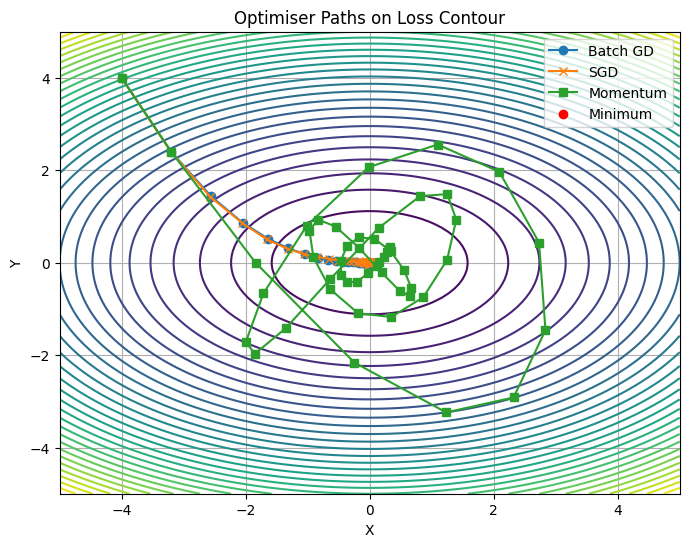


Training data shape: (800, 4)
Testing data shape: (200, 4)

All three models trained successfully!


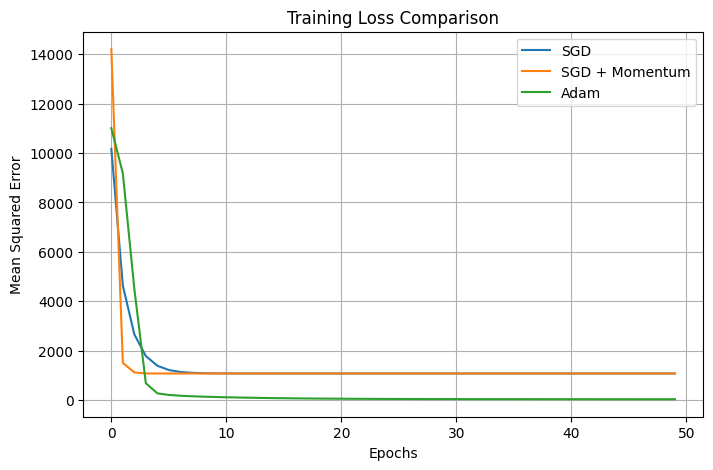

In [ ]:
# EXPERIMENT 6: GRADIENT DESCENT, SGD, MOMENTUM AND ADAM

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

np.random.seed(42)
tf.random.set_seed(42)

# --------------------------------------------------
# TASK 1: IMPLEMENT BATCH GD, SGD AND MOMENTUM
# --------------------------------------------------

def loss_function(x, y):
    return x**2 + 2*y**2

def gradient(x, y):
    return np.array([2*x, 4*y])

# Batch Gradient Descent
def batch_gd():
    x, y = -4.0, 4.0
    path = [(x, y)]

    for i in range(50):
        grad = gradient(x, y)
        x -= 0.1 * grad[0]
        y -= 0.1 * grad[1]
        path.append((x, y))

    return np.array(path)

# Stochastic Gradient Descent
def sgd():
    x, y = -4.0, 4.0
    path = [(x, y)]

    for i in range(50):
        grad = gradient(x, y)
        noise = np.random.normal(0, 0.1, 2)
        grad = grad + noise

        x -= 0.1 * grad[0]
        y -= 0.1 * grad[1]
        path.append((x, y))

    return np.array(path)

# Momentum
def momentum():
    x, y = -4.0, 4.0
    vx, vy = 0.0, 0.0
    path = [(x, y)]

    for i in range(50):
        grad = gradient(x, y)

        vx = 0.9 * vx + grad[0]
        vy = 0.9 * vy + grad[1]

        x -= 0.1 * vx
        y -= 0.1 * vy

        path.append((x, y))

    return np.array(path)

path_gd = batch_gd()
path_sgd = sgd()
path_momentum = momentum()

print("Batch GD Final Position:", path_gd[-1])
print("SGD Final Position:", path_sgd[-1])
print("Momentum Final Position:", path_momentum[-1])

# --------------------------------------------------
# TASK 2: PLOT OPTIMISER PATHS ON 2-D LOSS CONTOUR
# --------------------------------------------------

x = np.linspace(-5, 5, 100)
y = np.linspace(-5, 5, 100)

X, Y = np.meshgrid(x, y)
Z = X**2 + 2*Y**2

plt.figure(figsize=(8, 6))
plt.contour(X, Y, Z, levels=30)

plt.plot(path_gd[:, 0], path_gd[:, 1],
         marker='o', label='Batch GD')

plt.plot(path_sgd[:, 0], path_sgd[:, 1],
         marker='x', label='SGD')

plt.plot(path_momentum[:, 0], path_momentum[:, 1],
         marker='s', label='Momentum')

plt.scatter(0, 0, color='red', label='Minimum')

plt.title("Optimiser Paths on Loss Contour")
plt.xlabel("X")
plt.ylabel("Y")
plt.legend()
plt.grid()
plt.show()

# --------------------------------------------------
# TASK 3: CREATE DELIVERY TIME DATASET
# --------------------------------------------------

n = 1000

distance = np.random.uniform(1, 50, n)
traffic = np.random.uniform(1, 10, n)
weight = np.random.uniform(1, 20, n)
time_of_day = np.random.uniform(0, 24, n)

delivery_time = (
    10 + 2*distance + 3*traffic + 0.5*weight
    + 1.5*time_of_day
    + np.random.normal(0, 5, n)
)

X_data = np.column_stack(
    (distance, traffic, weight, time_of_day)
)

y_data = delivery_time

X_train, X_test, y_train, y_test = train_test_split(
    X_data, y_data, test_size=0.2, random_state=42
)

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print("\nTraining data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

# --------------------------------------------------
# TASK 3: TRAIN KERAS MODEL USING SGD, MOMENTUM AND ADAM
# --------------------------------------------------

def create_model():
    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(4,)),
        tf.keras.layers.Dense(16, activation='relu'),
        tf.keras.layers.Dense(8, activation='relu'),
        tf.keras.layers.Dense(1)
    ])

    return model

# SGD
model_sgd = create_model()

model_sgd.compile(
    optimizer=tf.keras.optimizers.SGD(learning_rate=0.01),
    loss='mse'
)

history_sgd = model_sgd.fit(
    X_train, y_train,
    epochs=50,
    batch_size=32,
    validation_split=0.2,
    verbose=0
)

# SGD WITH MOMENTUM
model_momentum = create_model()

model_momentum.compile(
    optimizer=tf.keras.optimizers.SGD(
        learning_rate=0.01, momentum=0.9
    ),
    loss='mse'
)

history_momentum = model_momentum.fit(
    X_train, y_train,
    epochs=50,
    batch_size=32,
    validation_split=0.2,
    verbose=0
)

# ADAM
model_adam = create_model()

model_adam.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.01),
    loss='mse'
)

history_adam = model_adam.fit(
    X_train, y_train,
    epochs=50,
    batch_size=32,
    validation_split=0.2,
    verbose=0
)

print("\nAll three models trained successfully!")

# --------------------------------------------------
# TASK 4: PLOT LOSS AGAINST EPOCHS
# --------------------------------------------------

plt.figure(figsize=(8, 5))

plt.plot(history_sgd.history['loss'], label='SGD')
plt.plot(history_momentum.history['loss'], label='SGD + Momentum')
plt.plot(history_adam.history['loss'], label='Adam')

plt.title("Training Loss Comparison")
plt.xlabel("Epochs")
plt.ylabel("Mean Squared Error")
plt.legend()
plt.grid()
plt.show()

# --------------------------------------------------
# TASK 5: VARY LEARNING RATE
# --------------------------------------------------

learning_rates = [0.001, 0.01, 0.1, 0.5]

plt.figure(figsize=(8, 5))

for lr in learning_rates:

    tf.keras.backend.clear_session()
    tf.random.set_seed(42)

    model = create_model()

    model.compile(
        optimizer=tf.keras.optimizers.SGD(learning_rate=lr),
        loss='mse'
    )

    history = model.fit(
        X_train, y_train,
        epochs=30,
        batch_size=32,
        validation_split=0.2,
        verbose=0
    )

    losses = np.array(history.history['loss'])

    # Display only finite losses
    valid = np.isfinite(losses)

    if np.any(valid):
        plt.plot(
            np.arange(1, len(losses)+1)[valid],
            losses[valid],
            label=f'LR={lr}'
        )

plt.title("Learning Rate Comparison")
plt.xlabel("Epochs")
plt.ylabel("Training Loss")
plt.legend()
plt.grid()
plt.show()

# --------------------------------------------------
# FINAL MODEL PERFORMANCE
# --------------------------------------------------

print("\nFinal Test MSE:")

print("SGD:", model_sgd.evaluate(X_test, y_test, verbose=0))
print("Momentum:", model_momentum.evaluate(X_test, y_test, verbose=0))
print("Adam:", model_adam.evaluate(X_test, y_test, verbose=0))

print("\nExperiment 6 Completed Successfully!")